## DiffGSP tutorial: human colorectal VisiumHD dataset


## DiffGSP tutorial: human colorectal cancer VisiumHD dataset

This tutorial demonstrates how to apply **DiffGSP** to a human colorectal cancer VisiumHD dataset.

The dataset was generated in the study:

**High definition spatial transcriptomic profiling of immune cell populations in colorectal cancer**

by Michelli F. Oliveira, Juan P. Romero, Meii Chung, et al.

The processed Visium HD spatial transcriptomics data are available from the 10x Genomics GitHub repository:

https://github.com/10XGenomics/HumanColonCancer_VisiumHD and downloaded from the [link](https://www.10xgenomics.com/products/visium-hd-spatial-gene-expression/dataset-human-crc).
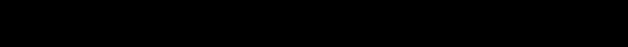

In [1]:
import DiffGSP as dg
import torch
import os
import numpy as np
import pandas as pd
import scanpy as sc
from pathlib import Path
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
import matplotlib.pyplot as plt

### 1. Define input and output paths

In [2]:
# define data path
data_dir = Path("/home/liujixin/datasets/VisiumHD")
res_dir = Path("/home/liujixin/project/DiffGSP/results/VisiumHD")
data_name = 'Human_Colorectal_Cancer'
res_dir = res_dir / data_name
data_dir = data_dir / data_name
if not res_dir.exists():
    res_dir.mkdir(parents=True)

### 2. Load data and obtian inital parameters

First, we process the 16 μm resolution data. Due to the large scale of Visium HD datasets, we perform parameter estimation on a down-sampled dataset to accelerate computation before applying DiffGSP to high-resolution data.

In [3]:
dg.seed_all(42)
# Set parameters
data_tissue = 'Human_Colorectal_Cancer'
square = '016'
data_type = 'VisiumHD'
method = 'BFGS'
k = 5

# Load data
data_name = 'P1'
data_path = data_dir / f'binned_outputs_{data_name}/square_{square}um'
tissue_position_file = f'{data_path}/spatial/tissue_positions.parquet'
tissue_position_csv = f'{data_path}/spatial/tissue_positions_list.csv'

if not os.path.exists(tissue_position_csv):
    tissue_position_df = pd.read_parquet(tissue_position_file)
    tissue_position_df.to_csv(tissue_position_csv, index=False, header=None)
adata = sc.read_visium(data_path, count_file='raw_feature_bc_matrix.h5')
adata.var_names_make_unique()

# down-sampling for parameter estimation
adata_down = dg.downsampling(adata, multiple=[8, 8])
adata_down = adata_down[:, dg.prefilter_genes(adata_down, min_cells=10)]
svgs = dg.select_svgs(adata_down, svg_method='gft_top', n_top=2000)
adata_down = adata_down[:, svgs]

Number of down-sampled spots: 2704


In [4]:
adata_down, optimal_solution, _, _ = dg.run_diffgsp(adata_down, k=k, device=device, method=method,
                                                    data_type=data_type, inv_cutoff='auto')

Training:  16%|█▉          | 16/100 [00:10<00:54,  1.54it/s, Loss=tensor(249.4118, device='cuda:0')]


New para 0.14849855
Current parameters: 	 [np.float32(0.14849855), array(0.09601372, dtype=float32)]


### 3. Run DiffGSP in 016 resolution

In [5]:
# run diffgsp normally (016)
dg.seed_all(42)
square = '016'
data_path = data_dir / f'binned_outputs_{data_name}/square_{square}um'
tissue_position_file = f'{data_path}/spatial/tissue_positions.parquet'
tissue_position_csv = f'{data_path}/spatial/tissue_positions_list.csv'

if not os.path.exists(tissue_position_csv):
    tissue_position_df = pd.read_parquet(tissue_position_file)
    tissue_position_df.to_csv(tissue_position_csv, index=False, header=None)
adata = sc.read_visium(data_path, count_file='raw_feature_bc_matrix.h5')
adata.var_names_make_unique()
adata = adata[:, svgs]
adata.write_h5ad(res_dir / f'{data_name}_square-{square}_Original.h5ad')

adata, optimal_solution16 = dg.run_diffgsp_subgraph(adata,
                                k=k,
                                device=device,
                                partition=[8, 8],
                                variable=optimal_solution,
                                data_type='VisiumHD',
                                gene_network=False,
                                inv_cutoff='auto')
adata.write_h5ad(res_dir / f'{data_name}_square-{square}_DiffGSP.h5ad')

(3969, 2000)
Found knee 0.20115907 1.25905
New para 0.20115907


Test: 100%|███████████████████████████████████████████| 64/64 [03:02<00:00,  2.85s/it, Finish=64/64]


### 4. Run DiffGSP in 008 resolution

In [6]:
# run diffgsp normally (008)
dg.seed_all(42)
square = '008'
data_path = data_dir / f'binned_outputs_{data_name}/square_{square}um'
tissue_position_file = f'{data_path}/spatial/tissue_positions.parquet'
tissue_position_csv = f'{data_path}/spatial/tissue_positions_list.csv'

if not os.path.exists(tissue_position_csv):
    tissue_position_df = pd.read_parquet(tissue_position_file)
    tissue_position_df.to_csv(tissue_position_csv, index=False, header=None)
adata = sc.read_visium(data_path, count_file='raw_feature_bc_matrix.h5')
adata.var_names_make_unique()
adata = adata[:, svgs]
adata.write_h5ad(res_dir / f'{data_name}_square-{square}_Original.h5ad')

adata, optimal_solution8 = dg.run_diffgsp_subgraph(adata,
                                k=k,
                                device=device,
                                partition=[16, 16],
                                variable=optimal_solution,
                                data_type='VisiumHD',
                                gene_network=False,
                                inv_cutoff='auto')
adata.write_h5ad(res_dir / f'{data_name}_square-{square}_DiffGSP_.h5ad')

(4032, 2000)
Found knee 0.2561329 1.2336214
New para 0.2561329


Test: 100%|███████████████████████████████████████| 256/256 [15:10<00:00,  3.56s/it, Finish=256/256]


### 5. Downstream analysis
We visualize several representative genes from the DiffGSP-corrected VisiumHD dataset to examine their spatial expression patterns.

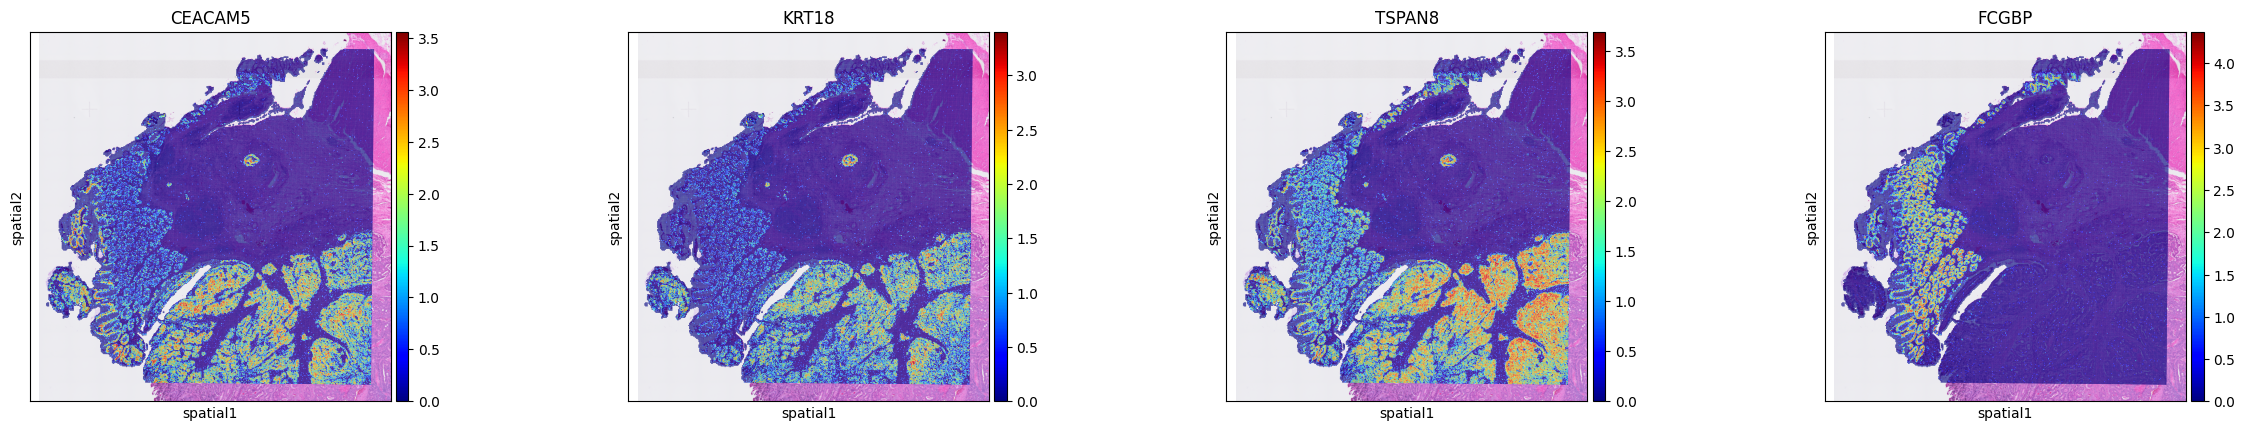

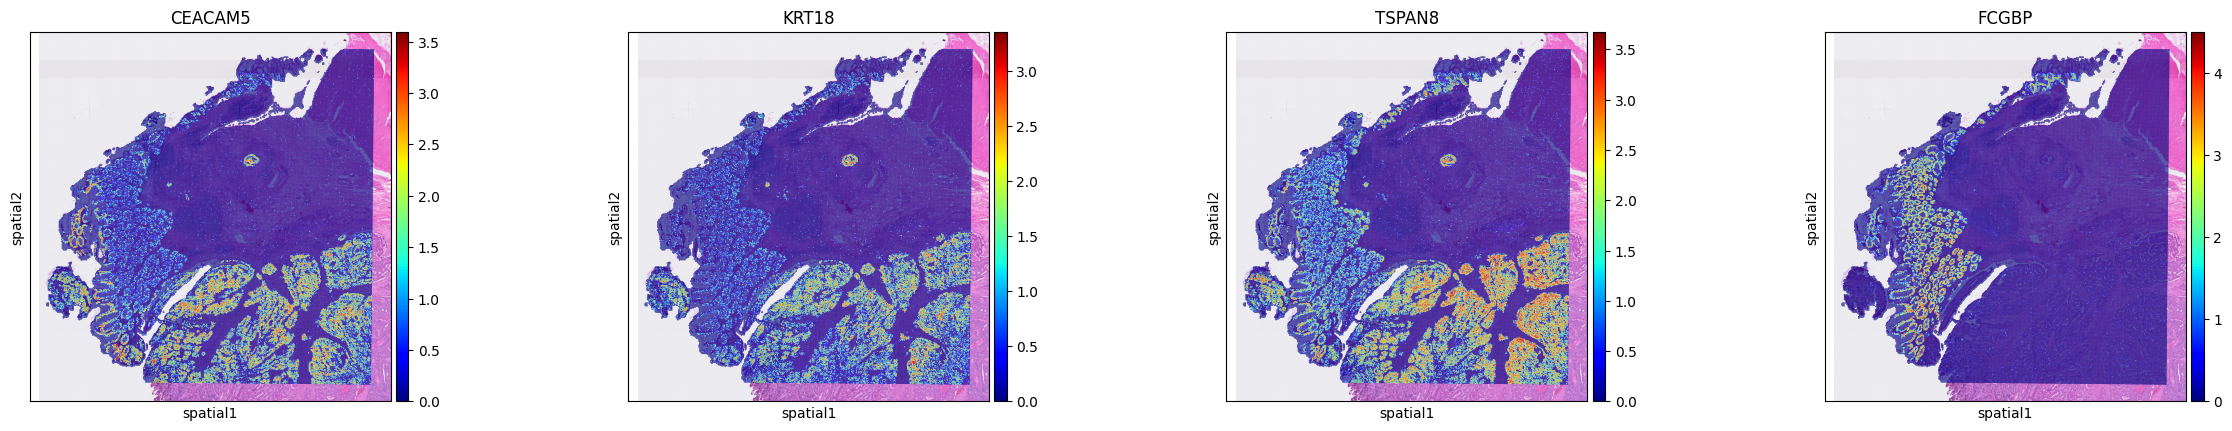

In [7]:
# load original and DiffGSP-corrected data
square = "016"

adata_orig = sc.read_h5ad(
    res_dir / f"{data_name}_square-{square}_Original.h5ad"
)

adata_diff = sc.read_h5ad(
    res_dir / f"{data_name}_square-{square}_DiffGSP.h5ad"
)
adata_diff.uns['spatial'] = adata_orig.uns['spatial'].copy() # add image

# keep in_tissue spots
adata_orig = adata_orig[adata_orig.obs['in_tissue'] == 1]
adata_diff = adata_diff[adata_diff.obs['in_tissue'] == 1]

# log transformation
sc.pp.log1p(adata_orig)
sc.pp.log1p(adata_diff)

gene_list = ["CEACAM5", "KRT18", "TSPAN8", "FCGBP"]
# visualization before correction
sc.pl.spatial(
    adata_orig,
    color=gene_list,
    cmap="jet",
)

# visualization after correction
sc.pl.spatial(
    adata_diff,
    color=gene_list,
    cmap="jet",
)